# IT Workshop Project

## Student Performance & Placement Analyzer

**Name:** Shinde Harshvardhan Sudhir  
**Roll No:** 2025bcs0221  
**Course:** IT Workshop


## Project Description
Student Performance & Placement Analyzer is a Python-based application designed to manage student records, analyze academic performance, and track placement information. It provides CRUD operations such as Add, View, Search, Update, and Delete, along with features like marks analysis, CGPA calculation, ranking, grading, placement eligibility, company-wise placement, and department-wise statistics. The project uses Object-Oriented Programming, NumPy, Pandas, Matplotlib, and CSV file handling to demonstrate practical Python programming and data analysis concepts.

## Student Performance & Placement Analytics System
This notebook manages student marks, calculates grades and CGPA, creates placement reports, and displays charts. Run the cells from top to bottom. The final cell starts the menu. Choose 0 to exit.

These libraries support CSV storage, calculations, data tables, and charts. The project saves records in students.csv in the current folder.

In [5]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SUBJECTS = ["Maths", "Physics", "Programming", "DBMS", "English"]
DEPARTMENTS = ["CSE", "ECE", "EEE", "MECH", "CIVIL", "CSY", "AIDS"]

DB_FILE = "students.db"

 Student class
The Student class stores a student’s details and calculates total marks, average, CGPA, pass status, and backlogs.

In [6]:
class Student:
    def __init__(self, roll, name, dept, marks, company="", package=0):
        self.roll = roll
        self.name = name
        self.dept = dept
        self.marks = marks
        self.company = company
        self.package = package

    def total(self):
        return sum(self.marks.values())

    def average(self):
        return self.total() / 5

    def cgpa(self):
        return self.average() / 10

    def passed(self):
        for mark in self.marks.values():
            if mark < 40:
                return False
        return True

    def backlogs(self):
        return [s for s, m in self.marks.items() if m < 40]

    def data(self):
        d = {
            "Roll": self.roll,
            "Name": self.name,
            "Department": self.dept
        }

        for s in SUBJECTS:
            d[s] = self.marks[s]

        d["Company"] = self.company
        d["Package"] = self.package

        return d

StudentManager loads and saves student records in the SQLite database, and finds students by roll number.

In [7]:
class StudentManager:
    def __init__(self):
        self.students = []
        self.connection = sqlite3.connect(DB_FILE)
        self.create_table()
        self.load()

    def create_table(self):
        self.connection.execute("""
            CREATE TABLE IF NOT EXISTS students (
                roll TEXT PRIMARY KEY,
                name TEXT NOT NULL,
                department TEXT NOT NULL,
                Maths REAL,
                Physics REAL,
                Programming REAL,
                DBMS REAL,
                English REAL,
                company TEXT DEFAULT '',
                package REAL DEFAULT 0
            )
        """)
        self.connection.commit()

    def load(self):
        query = """
            SELECT roll, name, department, Maths, Physics,
                   Programming, DBMS, English, company, package
            FROM students
        """

        rows = self.connection.execute(query).fetchall()

        for row in rows:
            marks = dict(zip(SUBJECTS, row[3:8]))

            company = row[8]
            if pd.isna(company):
                company = ""

            package = row[9]
            if pd.isna(package):
                package = 0

            self.students.append(
                Student(
                    str(row[0]),
                    row[1],
                    row[2],
                    marks,
                    company,
                    float(package)
                )
            )

    def save(self):
        query = """
            INSERT OR REPLACE INTO students
            (roll, name, department, Maths, Physics,
             Programming, DBMS, English, company, package)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """

        rows = []

        for student in self.students:
            row = [
                student.roll,
                student.name,
                student.dept
            ]

            row.extend(
                student.marks[subject]
                for subject in SUBJECTS
            )

            row.extend([
                student.company,
                student.package
            ])

            rows.append(row)

        self.connection.execute("DELETE FROM students")
        self.connection.executemany(query, rows)
        self.connection.commit()

    def find(self, roll):
        for student in self.students:
            if student.roll == roll:
                return student

        return None

Grade scale and student actions
This section contains the grade scale and functions to add, view, search, delete, and update student records

In [13]:
def grade(cgpa):
    if cgpa >= 9:
        return "A+"
    elif cgpa >= 8:
        return "A"
    elif cgpa >= 7:
        return "B+"
    elif cgpa >= 6:
        return "B"
    elif cgpa >= 5:
        return "C"
    else:
        return "F"


def add_student(manager):
    roll = input("Roll No: ").strip()
    name = input("Name: ").strip()
    dept = input("Department: ").strip().upper()

    if dept not in DEPARTMENTS:
        print("Invalid Department")
        return

    if manager.find(roll):
        print("Roll number already exists")
        return

    marks = {}

    for subject in SUBJECTS:
        while True:
            try:
                mark = float(input(subject + " marks: "))

                if 0 <= mark <= 100:
                    marks[subject] = mark
                    break

                print("Marks must be between 0 and 100")

            except ValueError:
                print("Enter a valid number")

    student = Student(roll, name, dept, marks)

    manager.students.append(student)
    manager.save()

    print("Student added successfully")

Class summary and placement reports
Review class CGPA statistics or summarize placement details by department or company.

In [6]:
def class_summary(manager):
    students=manager.students

    if not students:
        print("No students found")
        return

    cgpas=[s.cgpa() for s in students]

    print("\nCLASS SUMMARY")
    print("-"*40)
    print("Number of Students:",len(students))
    print("Average CGPA:",round(np.mean(cgpas),2))
    print("Highest CGPA:",round(max(cgpas),2))
    print("Lowest CGPA:",round(min(cgpas),2))

    failed=0
    for s in students:
        if not s.passed():
            failed+=1

    print("Failed Students:",failed)

    print("\nGRADES")
    for s in students:
        print(s.roll,s.name,grade(s.cgpa()))

def placement_report(manager):
    print("\nPLACEMENT REPORT")
    print("1. Department-wise")
    print("2. Company-wise")
    choice=input("Enter choice: ")

    if choice=="1":
        for dept in DEPARTMENTS:
            students=[s for s in manager.students if s.dept==dept]

            if students:
                placed=sum(1 for s in students if s.company)

                print(
                    dept,
                    "Students:",len(students),
                    "Placed:",placed,
                    "Average CGPA:",
                    round(np.mean([s.cgpa() for s in students]),2)
                )

    elif choice=="2":
        companies={s.company for s in manager.students if s.company}

        for company in companies:
            students=[
                s for s in manager.students
                if s.company==company
            ]

            print(
                company,
                "Students:",len(students),
                "Average CGPA:",
                round(np.mean([s.cgpa() for s in students]),2),
                "Package:",students[0].package,"LPA"
            )

    else:
        print("Invalid choice")

Charts
Select a chart from the submenu to view subject averages, department performance, CGPA distribution, placement percentage, or package distribution.

In [7]:
def charts(manager):
    students=manager.students

    if not students:
        print("No students found")
        return

    print("\nCHARTS")
    print("1. Subject Average")
    print("2. Department Performance")
    print("3. CGPA Distribution")
    print("4. Placement Percentage")
    print("5. Package Distribution")

    choice=input("Enter choice: ")

    if choice=="1":
        averages=[]

        for subject in SUBJECTS:
            values=[s.marks[subject] for s in students]
            averages.append(np.mean(values))

        plt.bar(SUBJECTS,averages)
        plt.title("Subject Average")
        plt.ylabel("Average Marks")
        plt.show()

    elif choice=="2":
        departments=[]
        averages=[]

        for dept in DEPARTMENTS:
            group=[s for s in students if s.dept==dept]

            if group:
                departments.append(dept)
                averages.append(
                    np.mean([s.cgpa() for s in group])
                )

        plt.bar(departments,averages)
        plt.title("Department Performance")
        plt.ylabel("Average CGPA")
        plt.show()

    elif choice=="3":
        cgpas=[s.cgpa() for s in students]

        plt.hist(cgpas,bins=5)
        plt.title("CGPA Distribution")
        plt.xlabel("CGPA")
        plt.ylabel("Students")
        plt.show()

    elif choice=="4":
        placed=sum(1 for s in students if s.company)
        not_placed=len(students)-placed

        plt.pie(
            [placed,not_placed],
            labels=["Placed","Not Placed"],
            autopct="%1.1f%%"
        )
        plt.title("Placement Percentage")
        plt.show()

    elif choice=="5":
        packages=[
            s.package for s in students
            if s.company
        ]

        if not packages:
            print("No placement data")
            return

        plt.hist(packages,bins=5)
        plt.title("Package Distribution")
        plt.xlabel("Package LPA")
        plt.ylabel("Students")
        plt.show()

    else:
        print("Invalid choice")

Main menu
The menu connects all project features. Running this final code cell starts the program automatically. Answer each prompt in the cell output; enter 0 when finished


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  1
Roll No:  317
Name:  prabhakar
Department:  cse
Maths marks:  98
Physics marks:  99
Programming marks:  96
DBMS marks:  93
English marks:  100


Student added successfully

===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  2



ALL STUDENTS
----------------------------------------------------------------------
277 mayur CSE CGPA: 9.5 Grade: A+
221 harsh CSE CGPA: 9.04 Grade: A+
37 abhinav ECE CGPA: 8.38 Grade: A
29 dev CSY CGPA: 6.22 Grade: B
301 tarun EEE CGPA: 7.02 Grade: B+
325 rohit MECH CGPA: 5.76 Grade: C
317 prabhakar CSE CGPA: 9.72 Grade: A+

TOPPERS
1 prabhakar 317 9.72
2 mayur 277 9.5
3 harsh 221 9.04

===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


...

Enter choice:  1


CSE Students: 3 Placed: 2 Average CGPA: 9.49
ECE Students: 1 Placed: 1 Average CGPA: 8.38
EEE Students: 1 Placed: 1 Average CGPA: 7.02
MECH Students: 1 Placed: 1 Average CGPA: 5.76
CSY Students: 1 Placed: 1 Average CGPA: 6.22

===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  8



CHARTS
1. Subject Average
2. Department Performance
3. CGPA Distribution
4. Placement Percentage
5. Package Distribution


Enter choice:  1


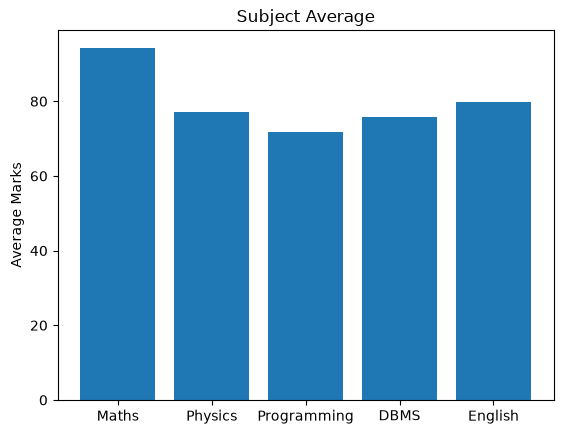


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  8



CHARTS
1. Subject Average
2. Department Performance
3. CGPA Distribution
4. Placement Percentage
5. Package Distribution


Enter choice:  2


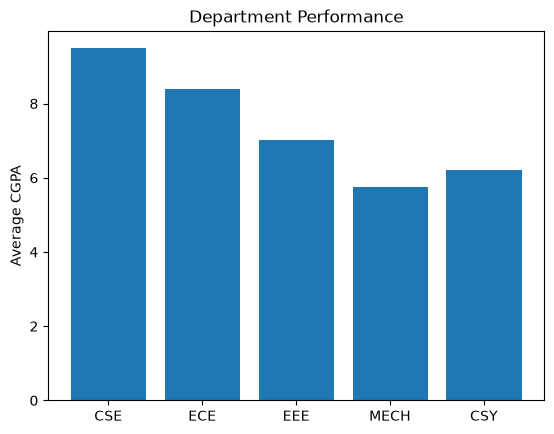


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  8



CHARTS
1. Subject Average
2. Department Performance
3. CGPA Distribution
4. Placement Percentage
5. Package Distribution


Enter choice:  3


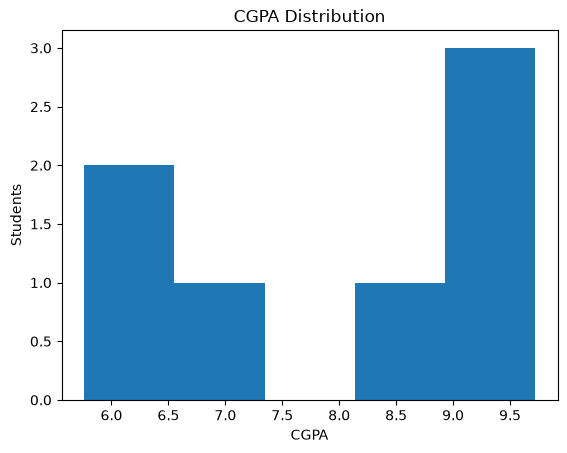


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  8



CHARTS
1. Subject Average
2. Department Performance
3. CGPA Distribution
4. Placement Percentage
5. Package Distribution


Enter choice:  4


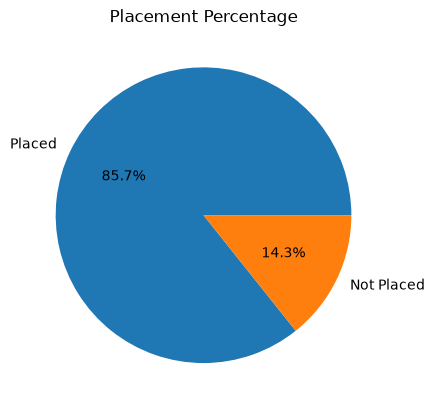


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  8



CHARTS
1. Subject Average
2. Department Performance
3. CGPA Distribution
4. Placement Percentage
5. Package Distribution


Enter choice:  5


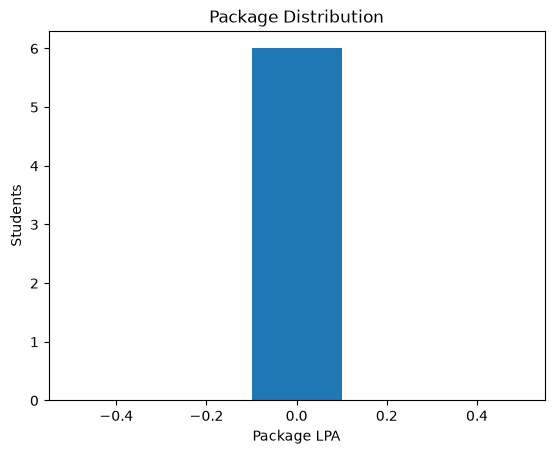


===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====
1. Add Student
2. View All Students with Toppers
3. Search Student
4. Delete Student
5. Update Marks
6. Class Summary
7. Placement Report
8. Charts
0. Exit


Enter choice:  0


Thank you


In [16]:
def main():
    manager=StudentManager()

    while True:
        print("\n===== STUDENT PERFORMANCE & PLACEMENT ANALYZER =====")
        print("1. Add Student")
        print("2. View All Students with Toppers")
        print("3. Search Student")
        print("4. Delete Student")
        print("5. Update Marks")
        print("6. Class Summary")
        print("7. Placement Report")
        print("8. Charts")
        print("0. Exit")

        choice=input("Enter choice: ")

        if choice=="1":
            add_student(manager)
        elif choice=="2":
            view_students(manager)
        elif choice=="3":
            search_student(manager)
        elif choice=="4":
            delete_student(manager)
        elif choice=="5":
            update_marks(manager)
        elif choice=="6":
            class_summary(manager)
        elif choice=="7":
            placement_report(manager)
        elif choice=="8":
            charts(manager)
        elif choice=="0":
            print("Thank you")
            break
        else:
            print("Invalid choice")

main()

